# 01 — Tổng quan dữ liệu, định dạng lưu trữ và phân chia tập

Notebook độc lập, không gọi `src/`. Tái sử dụng conversion theo batch, benchmark,
`get_dataframe_info`, `get_feature_info` và kiểm tra FK từ `01_eda.ipynb`.

**Các phần chính**
1. Thiết lập và kiểm tra đầu vào.
2. Chuyển CSV → Parquet; so sánh dung lượng và thời gian đọc.
3. Tổng quan hàng, cột và từ điển dữ liệu của từng bảng.
4. Kiểm tra khóa dự kiến, khóa ngoại và tính nhất quán quan hệ.
5. Cố định `train` (80% development), `val` (20% holdout) và 5 fold trên train.

**Đầu ra:** Parquet trong `data/interim/`; bảng CSV trong `reports/tables/`;
phân chia trong `data/splits/`. Không sửa raw, không làm sạch, không tạo đặc trưng,
không huấn luyện. Hai CSV phụ trợ (mô tả cột và submission mẫu) không phải bảng nghiệp vụ
nên không đưa vào benchmark tám bảng.

Thống kê toàn bộ bảng chỉ phục vụ kiểm kê chất lượng; không dùng thống kê holdout
để chọn đặc trưng hay fit preprocessing. Chỉ dùng TARGET để stratify và kiểm tra phân chia.


## 1. Thiết lập và kiểm tra đầu vào
Chạy từ repo root hoặc `notebooks/`. Dùng môi trường dự án đã có pandas, NumPy, PyArrow, scikit-learn, Matplotlib và IPython.


In [1]:
import hashlib
import json
import os
from datetime import datetime, timezone
from pathlib import Path
from statistics import median
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.csv as pc
import pyarrow.parquet as pq
from IPython.display import display
from sklearn.model_selection import StratifiedKFold, StratifiedShuffleSplit


def locate_project_root(cwd: Path) -> Path:
    override = os.getenv("HOME_CREDIT_ROOT")
    if override:
        root = Path(override).expanduser().resolve()
        if not (root / "data" / "raw").is_dir():
            raise FileNotFoundError(f"HOME_CREDIT_ROOT không chứa data/raw/: {root}")
        return root
    for folder in (cwd.resolve(), *cwd.resolve().parents):
        if (folder / "data" / "raw").is_dir():
            return folder
    raise FileNotFoundError("Không tìm thấy data/raw/. Đặt HOME_CREDIT_ROOT.")


ROOT = locate_project_root(Path.cwd())
RAW_DIR = ROOT / "data" / "raw"
INTERIM_DIR = ROOT / "data" / "interim"
REPORT_DIR = ROOT / "reports" / "tables"
SPLIT_DIR = ROOT / "data" / "splits"
TABLES = [
    "application_train", "application_test", "bureau", "bureau_balance",
    "previous_application", "POS_CASH_balance", "installments_payments",
    "credit_card_balance",
]
ID_COL, TARGET_COL = "SK_ID_CURR", "TARGET"
HOLDOUT_RATIO = 0.20
HOLDOUT_SEED = 2026  # Giữ protocol đã có trong 01_eda.ipynb.
CV_SEED = 42
N_FOLDS = 5
BENCHMARK_REPEATS = 3
BLOCK_SIZE = 16 * 1024 * 1024
BATCH_SIZE = 65_536
EXPORT_REPORTS = True  # False: kiểm tra notebook mà không ghi reports/.

INTERIM_DIR.mkdir(parents=True, exist_ok=True)
SPLIT_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 20)
plt.rcParams.update({"figure.figsize": (11, 5), "figure.dpi": 110})


def save_report(frame: pd.DataFrame, filename: str) -> None:
    if EXPORT_REPORTS:
        REPORT_DIR.mkdir(parents=True, exist_ok=True)
        frame.to_csv(REPORT_DIR / filename, index=False, encoding="utf-8-sig")


missing = [name for name in TABLES if not (RAW_DIR / f"{name}.csv").is_file()]
if missing:
    raise FileNotFoundError(f"Thiếu CSV bắt buộc: {missing}")
print(f"Root: {ROOT}")
print(f"Số bảng nghiệp vụ: {len(TABLES)}; benchmark: {BENCHMARK_REPEATS} lần/định dạng")


Root: D:\HCMUT\(HK261_CQ) LẬP TRÌNH CHO TRÍ TUỆ NHÂN TẠO VÀ KHOA HỌC DỮ LIỆU (CO3135)_TRẦN HUY\home-credit-risk
Số bảng nghiệp vụ: 8; benchmark: 3 lần/định dạng


## 2. CSV → Parquet và benchmark
Đọc và ghi theo batch để không giữ tất cả bảng trong RAM. Dùng Snappy và giữ giá trị gốc;
không downcast hay thay sentinel. Parquet đã có được tái sử dụng, không ghi đè.
File mới chỉ đổi sang tên chính thức sau khi ghi xong.

Benchmark đọc **toàn bộ cột và toàn bộ hàng qua Arrow batches**, không materialize cả bảng
thành pandas. Lấy median của 3 lần, đảo thứ tự CSV/Parquet giữa các lần.
Đây là thời gian đọc/giải mã với cache hệ điều hành hiện tại, không phải cold-cache benchmark
hay thời gian `pd.read_csv`/`pd.read_parquet`. Thời gian conversion đo riêng.

- `storage_saved_mib = csv_mib − parquet_mib`; `storage_reduction_pct = (1 − parquet_bytes/csv_bytes) × 100`.
- `read_speedup = csv_read_s/parquet_read_s` (lớn hơn 1 là nhanh hơn).
- `read_time_change_pct = (parquet_read_s/csv_read_s − 1) × 100` (âm là giảm thời gian).
- `read_time_saved_pct = (1 − parquet_read_s/csv_read_s) × 100`.

Các kiểm tra số hàng và tên cột không chứng minh mọi giá trị của Parquet có sẵn giống CSV.
Nếu nghi ngờ nguồn Parquet cũ, cần đối soát nội dung trước khi sử dụng tiếp.


In [4]:
def convert_table(table: str) -> dict:
    source = RAW_DIR / f"{table}.csv"
    destination = INTERIM_DIR / f"{table}.parquet"
    if destination.exists():
        pq.ParquetFile(destination)  # Không chấp nhận file hỏng.
        return {"table": table, "conversion_status": "reused", "conversion_s": np.nan}
    temporary = destination.with_suffix(".parquet.inprogress")
    if temporary.exists():
        raise FileExistsError(f"Có conversion chưa hoàn tất, cần kiểm tra: {temporary}")
    start = perf_counter()
    with pc.open_csv(source, read_options=pc.ReadOptions(block_size=BLOCK_SIZE)) as reader:
        with pq.ParquetWriter(temporary, reader.schema, compression="snappy") as writer:
            for batch in reader:
                writer.write_batch(batch)
    temporary.rename(destination)
    return {"table": table, "conversion_status": "created",
     "conversion_s": perf_counter() - start}


conversion_df = pd.DataFrame([convert_table(table) for table in TABLES])
display(conversion_df)


,table,conversion_status,conversion_s
0,application_train,created,6.416825
1,application_test,created,1.049426
2,bureau,created,6.403303
3,bureau_balance,created,7.477297
4,previous_application,created,13.001974
5,POS_CASH_balance,created,11.315519
6,installments_payments,created,21.484107
7,credit_card_balance,created,16.538797


In [5]:
def benchmark_csv(path: Path) -> tuple[float, int, list[str]]:
    start = perf_counter()
    with pc.open_csv(path, read_options=pc.ReadOptions(block_size=BLOCK_SIZE)) as reader:
        names = reader.schema.names
        n_rows = sum(batch.num_rows for batch in reader)
    return perf_counter() - start, n_rows, names


def benchmark_parquet(path: Path) -> tuple[float, int, list[str]]:
    start = perf_counter()
    with pq.ParquetFile(path) as reader:
        names = reader.schema_arrow.names
        n_rows = sum(batch.num_rows for batch in reader.iter_batches(batch_size=BATCH_SIZE))
    return perf_counter() - start, n_rows, names


benchmark_rows, benchmark_runs = [], []
for table in TABLES:
    paths = {"csv": RAW_DIR / f"{table}.csv", "parquet": INTERIM_DIR / f"{table}.parquet"}
    elapsed = {"csv": [], "parquet": []}
    expected_rows = pq.ParquetFile(paths["parquet"]).metadata.num_rows
    expected_columns = pq.read_schema(paths["parquet"]).names
    for repeat in range(BENCHMARK_REPEATS):
        order = ("csv", "parquet") if repeat % 2 == 0 else ("parquet", "csv")
        for fmt in order:
            reader = benchmark_csv if fmt == "csv" else benchmark_parquet
            seconds, n_rows, names = reader(paths[fmt])
            assert n_rows == expected_rows and names == expected_columns, table
            elapsed[fmt].append(seconds)
            benchmark_runs.append({"table": table, "repeat": repeat + 1, "format": fmt,
                                   "read_s": seconds, "n_rows": n_rows})
    csv_bytes, parquet_bytes = (paths[fmt].stat().st_size for fmt in ("csv", "parquet"))
    csv_s, parquet_s = (median(elapsed[fmt]) for fmt in ("csv", "parquet"))
    benchmark_rows.append({
        "table": table, "n_rows": expected_rows, "n_columns": len(expected_columns),
        "csv_mib": csv_bytes / 1024**2, "parquet_mib": parquet_bytes / 1024**2,
        "storage_saved_mib": (csv_bytes - parquet_bytes) / 1024**2,
        "storage_reduction_pct": (1 - parquet_bytes / csv_bytes) * 100,
        "csv_read_s": csv_s, "parquet_read_s": parquet_s,
        "read_speedup": csv_s / parquet_s,
        "read_time_change_pct": (parquet_s / csv_s - 1) * 100,
        "read_time_saved_pct": (1 - parquet_s / csv_s) * 100,
    })
    print(f"[CHECKED] {table}: {expected_rows:,} hàng")

benchmark_df = pd.DataFrame(benchmark_rows).merge(conversion_df, on="table", validate="one_to_one")
save_report(benchmark_df, "storage_benchmark.csv")
save_report(pd.DataFrame(benchmark_runs), "storage_benchmark_runs.csv")
display(benchmark_df.round(3))


[CHECKED] application_train: 307,511 hàng
[CHECKED] application_test: 48,744 hàng
[CHECKED] bureau: 1,716,428 hàng
[CHECKED] bureau_balance: 27,299,925 hàng
[CHECKED] previous_application: 1,670,214 hàng
[CHECKED] POS_CASH_balance: 10,001,358 hàng
[CHECKED] installments_payments: 13,605,401 hàng
[CHECKED] credit_card_balance: 3,840,312 hàng


,table,n_rows,n_columns,csv_mib,parquet_mib,storage_saved_mib,storage_reduction_pct,csv_read_s,parquet_read_s,read_speedup,read_time_change_pct,read_time_saved_pct,conversion_status,conversion_s
0,application_train,307511,122,158.437,26.377,132.060,83.352,4.342,0.090,48.346,-97.932,97.932,created,6.417
1,application_test,48744,121,25.337,4.384,20.953,82.698,0.690,0.026,26.924,-96.286,96.286,created,1.049
2,bureau,1716428,17,162.141,37.746,124.395,76.720,3.153,0.186,16.981,-94.111,94.111,created,6.403
3,bureau_balance,27299925,3,358.193,15.868,342.326,95.570,4.487,1.295,3.466,-71.149,71.149,created,7.477
4,previous_application,1670214,37,386.213,72.159,314.054,81.316,8.265,0.476,17.365,-94.241,94.241,created,13.002
5,POS_CASH_balance,10001358,8,374.511,123.668,250.843,66.979,6.069,0.617,9.830,-89.827,89.827,created,11.316
6,installments_payments,13605401,8,689.619,280.124,409.496,59.380,12.982,0.564,23.016,-95.655,95.655,created,21.484
7,credit_card_balance,3840312,23,404.914,126.586,278.327,68.737,11.655,0.453,25.705,-96.110,96.110,created,16.539


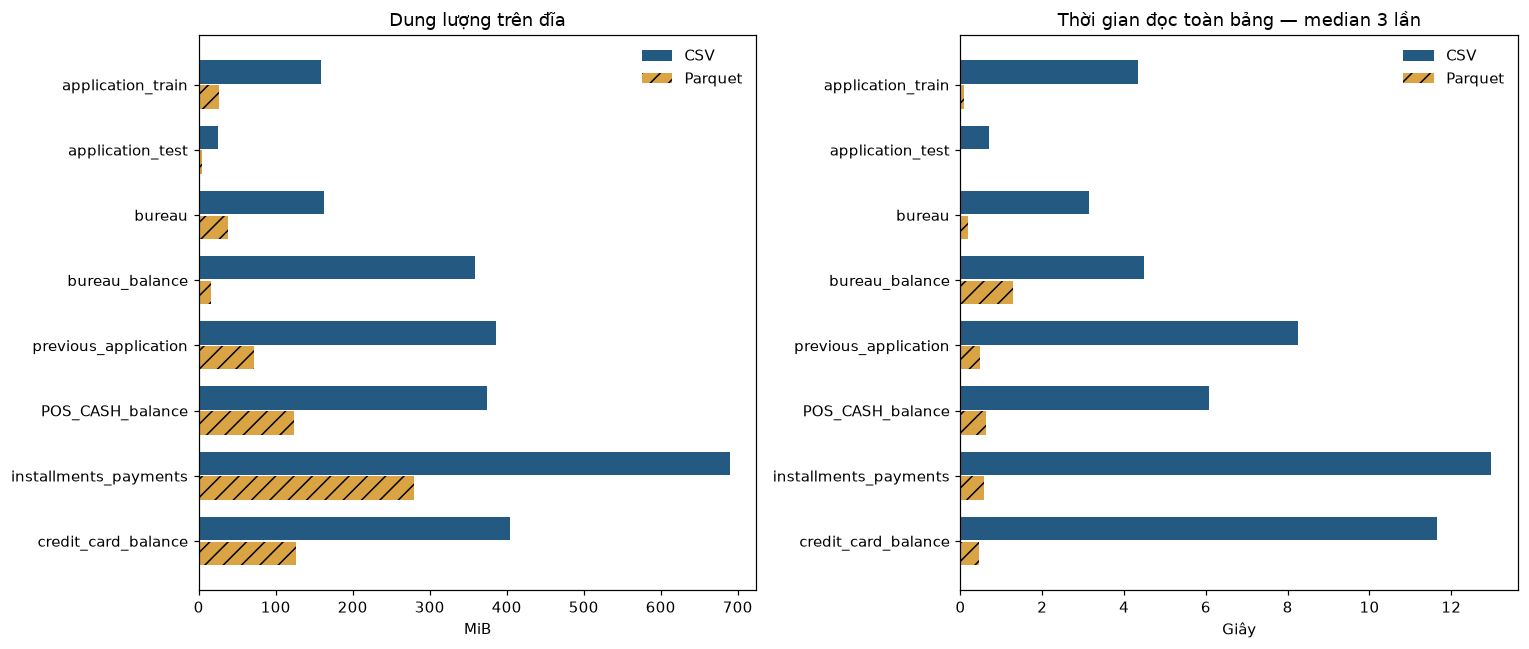

Tiết kiệm tổng dung lượng: 1,872.45 MiB
Speedup và phần trăm thay đổi của từng bảng nằm trong storage_benchmark.csv.


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
y = np.arange(len(benchmark_df))
for ax, columns, title, unit in [
    (axes[0], ["csv_mib", "parquet_mib"], "Dung lượng trên đĩa", "MiB"),
    (axes[1], ["csv_read_s", "parquet_read_s"], "Thời gian đọc toàn bảng — median 3 lần", "Giây"),
]:
    for offset, column, label, color, hatch in [
        (-0.19, columns[0], "CSV", "#245A81", ""),
        (0.19, columns[1], "Parquet", "#DAA343", "//"),
    ]:
        ax.barh(y + offset, benchmark_df[column], height=0.36, label=label, color=color, hatch=hatch)
    ax.set_yticks(y, benchmark_df["table"])
    ax.invert_yaxis()
    ax.set(title=title, xlabel=unit)
    ax.set_xlim(left=0)
    ax.legend(frameon=False)
fig.tight_layout()
plt.show()
print(f"Tiết kiệm tổng dung lượng: {benchmark_df.storage_saved_mib.sum():,.2f} MiB")
print("Speedup và phần trăm thay đổi của từng bảng nằm trong storage_benchmark.csv.")


## 3. Tổng quan hàng, cột và từ điển dữ liệu
Mỗi vòng chỉ giữ một bảng trong RAM. Thống kê đầy đủ trên dữ liệu gốc, không sampling:
số hàng/cột, kiểu dữ liệu vật lý, missing, duplicate toàn dòng; với từng cột có cardinality,
mode và mô tả từ `HomeCredit_columns_description.csv`.

`n_unique` bỏ qua null; `unique_rate` và `mode_rate` dùng số giá trị không thiếu làm mẫu số.
Kiểu dữ liệu vật lý không đồng nghĩa vai trò nghiệp vụ: mã số nguyên có thể là categorical.
Duplicate trong bảng lịch sử được ghi nhận, chưa tự động xóa.


In [7]:
from pandas.api.types import is_string_dtype

def get_dataframe_info(df: pd.DataFrame) -> pd.DataFrame:
    n_rows, n_cols = df.shape
    total_cells = n_rows * n_cols

    # Physical data types
    dtypes = df.dtypes.astype(str)

    n_int64_columns = dtypes.isin(["int64", "Int64"]).sum()
    n_float64_columns = dtypes.isin(["float64", "Float64"]).sum()
    n_string_columns = sum(
        is_string_dtype(dtype) for dtype in df.dtypes
    )

    # Identifier columns (based on column names)
    n_id_columns = sum(
        col.upper().startswith("SK_ID_")
        or col.upper() == "ID"
        or col.upper().endswith("_ID")
        for col in df.columns
    )

    # Constant columns (including missing values)
    n_constant_columns = (
        df.nunique(dropna=False) == 1
    ).sum()

    # Missing values
    missing_mask = df.isna()
    n_missing_cells = missing_mask.sum().sum()
    missing_rate = (
        n_missing_cells / total_cells if total_cells else 0.0
    )

    n_rows_with_missing = missing_mask.any(axis=1).sum()
    n_columns_with_missing = missing_mask.any(axis=0).sum()

    # Duplicate rows
    n_duplicate_rows = df.duplicated().sum()
    duplicate_rate = (
        n_duplicate_rows / n_rows if n_rows else 0.0
    )

    return pd.DataFrame([{
        "n_rows": int(n_rows),
        "n_cols": int(n_cols),
        "n_int64_columns": int(n_int64_columns),
        "n_float64_columns": int(n_float64_columns),
        "n_string_columns": int(n_string_columns),
        "n_id_columns": int(n_id_columns),
        "n_constant_columns": int(n_constant_columns),
        "n_missing_cells": int(n_missing_cells),
        "missing_rate": float(missing_rate),
        "n_rows_with_missing": int(n_rows_with_missing),
        "n_columns_with_missing": int(n_columns_with_missing),
        "n_duplicate_rows": int(n_duplicate_rows),
        "memory_mib": float(df.memory_usage(deep=True).sum() / 1024**2),
        "duplicate_rate": float(duplicate_rate),
    }])


In [8]:
def get_feature_info(
    df: pd.DataFrame,
    description_df: pd.DataFrame,
    table_name: str,
) -> pd.DataFrame:
    n_rows = len(df)
    results = []

    table_key = table_name.removesuffix(".csv").lower()
    descriptions = description_df.copy()
    descriptions["Table"] = (
        descriptions["Table"]
        .astype("string")
        .str.strip()
    )
    descriptions["Row"] = (
        descriptions["Row"]
        .astype("string")
        .str.strip()
    )
    source_table = (
        descriptions["Table"]
        .str.lower()
        .str.removesuffix(".csv")
    )

    if table_key in ("application_train", "application_test"):
        mask = source_table.str.contains(
            "application_", regex=False, na=False
        )
    else:
        mask = source_table.eq(table_key).fillna(False)
    descriptions = descriptions.loc[mask].copy()

    metadata_columns = [
        col for col in descriptions.columns
        if col not in ("Row",)
        and not col.startswith("Unnamed:")
    ]
    def combine_values(series):
        values = (
            series.dropna()
            .astype(str)
            .str.strip()
        )
        values = values[values.ne("")].unique()
        return " | ".join(values) if len(values) else pd.NA
    metadata = (
        descriptions
        .groupby("Row", dropna=True)[metadata_columns]
        .agg(combine_values)
    )

    for col in df.columns:
        s = df[col]
        n_non_missing = int(s.count())
        n_missing = n_rows - n_non_missing
        missing_rate = (
            n_missing / n_rows if n_rows else np.nan
        )
        counts = s.value_counts(dropna=True)
        n_unique = len(counts)
        unique_rate = (
            n_unique / n_non_missing
            if n_non_missing else np.nan
        )
        mode = counts.index[0] if n_unique else pd.NA
        mode_frequency = int(counts.iloc[0]) if n_unique else 0
        mode_rate = (
            mode_frequency / n_non_missing
            if n_non_missing else np.nan
        )
        feature_metadata = (
            metadata.loc[col].to_dict()
            if col in metadata.index
            else {}
        )

        results.append({
            "feature": col,
            **feature_metadata,
            "dtype": str(s.dtype),
            "n_non_missing": n_non_missing,
            "n_missing": n_missing,
            "missing_rate": missing_rate,
            "n_unique": n_unique,
            "unique_rate": unique_rate,
            "mode": mode,
            "mode_frequency": mode_frequency,
            "mode_rate": mode_rate,
        })

    result_df = pd.DataFrame(results)
    result_df = result_df.rename(columns={
        "Table": "source_table",
        "Description": "description",
        "Special": "special",
    })

    description_columns = [
        "feature",
        "source_table",
        "description",
        "special",
    ]
    statistic_columns = [
        "dtype",
        "n_non_missing",
        "n_missing",
        "missing_rate",
        "n_unique",
        "unique_rate",
        "mode",
        "mode_frequency",
        "mode_rate",
    ]
    extra_columns = [
        col for col in result_df.columns
        if col not in description_columns + statistic_columns
    ]
    return result_df.reindex(columns=(
        description_columns
        + extra_columns
        + statistic_columns
    ))


In [9]:
description_path = RAW_DIR / "HomeCredit_columns_description.csv"
if description_path.is_file():
    description_df = pd.read_csv(description_path, encoding="cp1252")
else:
    description_df = pd.DataFrame(columns=["Table", "Row", "Description", "Special"])
    print("Thiếu từ điển mô tả tùy chọn; các thống kê vẫn được tính đầy đủ.")

overview_parts, feature_parts = [], []
for table in TABLES:
    df = pd.read_parquet(INTERIM_DIR / f"{table}.parquet")
    info = get_dataframe_info(df)
    info.insert(0, "table", table)
    overview_parts.append(info)
    features = get_feature_info(df, description_df, table)
    features.insert(0, "table", table)
    feature_parts.append(features)
    print(f"[PROFILED] {table}: {df.shape[0]:,} hàng × {df.shape[1]} cột")
    del df

overview_df = pd.concat(overview_parts, ignore_index=True)
feature_info_df = pd.concat(feature_parts, ignore_index=True)
save_report(overview_df, "dataframe_overview.csv")
save_report(feature_info_df, "feature_information.csv")
display(overview_df.round(4))
display(feature_info_df.sort_values("missing_rate", ascending=False).head(20))


[PROFILED] application_train: 307,511 hàng × 122 cột
[PROFILED] application_test: 48,744 hàng × 121 cột
[PROFILED] bureau: 1,716,428 hàng × 17 cột
[PROFILED] bureau_balance: 27,299,925 hàng × 3 cột
[PROFILED] previous_application: 1,670,214 hàng × 37 cột
[PROFILED] POS_CASH_balance: 10,001,358 hàng × 8 cột
[PROFILED] installments_payments: 13,605,401 hàng × 8 cột
[PROFILED] credit_card_balance: 3,840,312 hàng × 23 cột


,table,n_rows,n_cols,n_int64_columns,n_float64_columns,n_string_columns,n_id_columns,n_constant_columns,n_missing_cells,missing_rate,n_rows_with_missing,n_columns_with_missing,n_duplicate_rows,memory_mib,duplicate_rate
0,application_train,307511,122,41,65,16,1,0,8388094,0.2236,296160,61,0,324.9956,0.0
1,application_test,48744,121,40,65,16,1,11,1285385,0.2179,46348,58,0,51.1281,0.0
2,bureau,1716428,17,6,8,3,2,0,3939947,0.1350,1676762,7,0,271.4845,0.0
3,bureau_balance,27299925,3,2,0,1,1,0,0,0.0000,0,0,0,650.8811,0.0
4,previous_application,1670214,37,6,15,16,2,0,10288585,0.1665,1664642,14,0,671.4132,0.0
5,POS_CASH_balance,10001358,8,5,2,1,2,0,52158,0.0007,26184,2,0,669.8863,0.0
6,installments_payments,13605401,8,3,5,0,2,0,5810,0.0001,2905,2,0,830.4079,0.0
7,credit_card_balance,3840312,23,7,15,1,2,0,5877356,0.0665,826036,9,0,696.2297,0.0


,table,feature,source_table,description,special,dtype,n_non_missing,n_missing,missing_rate,n_unique,unique_rate,mode,mode_frequency,mode_rate
277,previous_application,RATE_INTEREST_PRIVILEGED,previous_application.csv,Interest rate normalized on previous credit,normalized,float64,5951,1664263,0.996437,25,0.004201,0.835095,1717,0.288523
276,previous_application,RATE_INTEREST_PRIMARY,previous_application.csv,Interest rate normalized on previous credit,normalized,float64,5951,1664263,0.996437,148,0.024870,0.189136,1218,0.204671
259,bureau,AMT_ANNUITY,bureau.csv,Annuity of the Credit Bureau credit,NaN,float64,489637,1226791,0.714735,40321,0.082349,0.0,256915,0.524705
62,application_train,COMMONAREA_MODE,application_{train|test}.csv,Normalized information about building where th...,normalized,float64,92646,214865,0.698723,3128,0.033763,0.0,9690,0.104592
48,application_train,COMMONAREA_AVG,application_{train|test}.csv,Normalized information about building where th...,normalized,float64,92646,214865,0.698723,3181,0.034335,0.0,8442,0.091121
76,application_train,COMMONAREA_MEDI,application_{train|test}.csv,Normalized information about building where th...,normalized,float64,92646,214865,0.698723,3202,0.034562,0.0,8691,0.093809
70,application_train,NONLIVINGAPARTMENTS_MODE,application_{train|test}.csv,Normalized information about building where th...,normalized,float64,93997,213514,0.694330,167,0.001777,0.0,59255,0.630392
84,application_train,NONLIVINGAPARTMENTS_MEDI,application_{train|test}.csv,Normalized information about building where th...,normalized,float64,93997,213514,0.694330,214,0.002277,0.0,56097,0.596796
56,application_train,NONLIVINGAPARTMENTS_AVG,application_{train|test}.csv,Normalized information about building where th...,normalized,float64,93997,213514,0.694330,386,0.004107,0.0,54549,0.580327
197,application_test,COMMONAREA_MEDI,application_{train|test}.csv,Normalized information about building where th...,normalized,float64,15249,33495,0.687161,2034,0.133386,0.0,1425,0.093449


## 4. Khóa và quan hệ giữa các bảng

| Bảng | Một dòng biểu diễn | Khóa dự kiến cần kiểm tra |
|---|---|---|
| application_train / application_test | Một hồ sơ hiện tại | SK_ID_CURR |
| bureau | Một khoản tín dụng ở tổ chức khác | SK_ID_BUREAU |
| bureau_balance | Một tháng của khoản bureau | SK_ID_BUREAU + MONTHS_BALANCE |
| previous_application | Một đơn vay trước đây | SK_ID_PREV |
| POS_CASH_balance / credit_card_balance | Một snapshot tháng của khoản vay | SK_ID_PREV + MONTHS_BALANCE |
| installments_payments | Một lần trả tiền hoặc bản ghi kỳ trả | Tổ hợp chẩn đoán, chưa khẳng định PK |

Khóa dự kiến chỉ đạt **NOT NULL + UNIQUE** khi kiểm tra trên toàn bảng.
Đây là kiểm tra superkey thực nghiệm, không chứng minh khóa tối thiểu hay ràng buộc PK của hệ thống gốc.
Đặc biệt installments có thể có nhiều lần thanh toán cho một kỳ: không tự loại trùng
hay vét cạn mọi tổ hợp cột để tìm một khóa có vẻ duy nhất.


In [10]:
KEY_PREDICTIONS = {
    "application_train": [ID_COL], "application_test": [ID_COL],
    "bureau": ["SK_ID_BUREAU"],
    "bureau_balance": ["SK_ID_BUREAU", "MONTHS_BALANCE"],
    "previous_application": ["SK_ID_PREV"],
    "POS_CASH_balance": ["SK_ID_PREV", "MONTHS_BALANCE"],
    "credit_card_balance": ["SK_ID_PREV", "MONTHS_BALANCE"],
    "installments_payments": ["SK_ID_PREV", "NUM_INSTALMENT_VERSION", "NUM_INSTALMENT_NUMBER",
                              "DAYS_ENTRY_PAYMENT", "AMT_PAYMENT"],
}


def check_candidate_key(df: pd.DataFrame, keys: list[str]) -> dict:
    if not keys or len(set(keys)) != len(keys) or not set(keys).issubset(df.columns):
        raise ValueError(f"Khóa không hợp lệ: {keys}")
    n_null = int(df[keys].isna().any(axis=1).sum())
    duplicates = df.duplicated(subset=keys, keep=False)
    return {
        "key_columns": " + ".join(keys), "n_rows": len(df),
        "n_null_key_rows": n_null,
        "n_duplicate_key_rows": int(duplicates.sum()),
        "n_duplicate_key_excess": int(df.duplicated(subset=keys).sum()),
        "passes_not_null_unique": bool(len(df) > 0 and n_null == 0 and not duplicates.any()),
        "duplicate_examples": json.dumps(df.loc[duplicates, keys].head(3).to_dict("records")),
    }


key_rows = []
for table, keys in KEY_PREDICTIONS.items():
    df = pd.read_parquet(INTERIM_DIR / f"{table}.parquet", columns=keys)
    key_rows.append({"table": table,
                     "role": "diagnostic_combination" if table == "installments_payments" else "expected_primary_key",
                     **check_candidate_key(df, keys)})
    del df
key_validation_df = pd.DataFrame(key_rows)
save_report(key_validation_df, "primary_key_validation.csv")
display(key_validation_df.drop(columns="duplicate_examples"))


,table,role,key_columns,n_rows,n_null_key_rows,n_duplicate_key_rows,n_duplicate_key_excess,passes_not_null_unique
0,application_train,expected_primary_key,SK_ID_CURR,307511,0,0,0,True
1,application_test,expected_primary_key,SK_ID_CURR,48744,0,0,0,True
2,bureau,expected_primary_key,SK_ID_BUREAU,1716428,0,0,0,True
3,bureau_balance,expected_primary_key,SK_ID_BUREAU + MONTHS_BALANCE,27299925,0,0,0,True
4,previous_application,expected_primary_key,SK_ID_PREV,1670214,0,0,0,True
5,POS_CASH_balance,expected_primary_key,SK_ID_PREV + MONTHS_BALANCE,10001358,0,0,0,True
6,credit_card_balance,expected_primary_key,SK_ID_PREV + MONTHS_BALANCE,3840312,0,0,0,True
7,installments_payments,diagnostic_combination,SK_ID_PREV + NUM_INSTALMENT_VERSION + NUM_INST...,13605401,2905,0,0,False


### 4.1. Khóa ngoại và chủ sở hữu khoản vay
Dùng hợp `application_train` + `application_test` làm bảng cha khách hàng, tránh đánh nhầm
khách hàng test là orphan. Kiểm tra cả `SK_ID_PREV` riêng và cặp `(SK_ID_PREV, SK_ID_CURR)`
để phát hiện khoản vay ghép sai chủ. Bảng lịch sử còn được đối chiếu trực tiếp với application.
Null FK và orphan được báo riêng; quan hệ chỉ đạt khi khóa cha hợp lệ và cả hai đều bằng 0.
Các orphan chỉ là phát hiện trong bộ dữ liệu được cung cấp; không tự xóa bản ghi.


In [11]:
def check_foreign_key(
    child_df: pd.DataFrame,
    parent_df: pd.DataFrame,
    foreign_keys: list[str],
    reference_keys: list[str] | None = None,
    sample_size: int = 5,
) -> dict:

    reference_keys = (
        foreign_keys if reference_keys is None else reference_keys
    )

    if not foreign_keys or len(foreign_keys) != len(reference_keys):
        raise ValueError("Foreign keys and reference keys must have equal non-zero lengths.")

    if len(set(foreign_keys)) != len(foreign_keys):
        raise ValueError("Foreign keys contain duplicate columns.")

    if len(set(reference_keys)) != len(reference_keys):
        raise ValueError("Reference keys contain duplicate columns.")

    if not set(foreign_keys).issubset(child_df.columns):
        raise ValueError("Foreign key columns not found in child table.")

    if not set(reference_keys).issubset(parent_df.columns):
        raise ValueError("Reference key columns not found in parent table.")

    # ===== 1. NULL VALIDATION =====
    child_null_mask = child_df[foreign_keys].isna().any(axis=1)
    parent_null_mask = parent_df[reference_keys].isna().any(axis=1)

    n_child_null = int(child_null_mask.sum())
    n_parent_null = int(parent_null_mask.sum())

    # ===== 2. PARENT KEY VALIDATION =====
    parent_keys = parent_df.loc[
        ~parent_null_mask, reference_keys
    ].copy()

    n_parent_duplicates = int(parent_keys.duplicated().sum())

    is_valid_reference_key = (
        n_parent_null == 0
        and n_parent_duplicates == 0
    )

    # ===== 3. FOREIGN KEY MATCHING =====
    child_keys = child_df.loc[
        ~child_null_mask, foreign_keys
    ]

    key_counts = (
        child_keys
        .value_counts(sort=False)
        .rename("row_count")
        .reset_index()
    )

    # Align key names before joining
    parent_keys.columns = foreign_keys
    parent_keys = parent_keys.drop_duplicates()

    matched = key_counts.merge(
        parent_keys.assign(_matched=True),
        on=foreign_keys,
        how="left",
        validate="one_to_one",
    )

    orphan_mask = matched["_matched"].isna()

    n_orphan_rows = int(
        matched.loc[orphan_mask, "row_count"].sum()
    )

    n_orphan_keys = int(orphan_mask.sum())
    n_checked_rows = len(child_keys)

    orphan_samples = (
        matched.loc[orphan_mask, foreign_keys]
        .head(sample_size)
        .to_dict("records")
    )

    # ===== 4. RESULT =====
    return {
        "foreign_keys": foreign_keys,
        "reference_keys": reference_keys,
        "is_valid_reference_key": bool(is_valid_reference_key),
        "n_child_rows": int(len(child_df)),
        "n_checked_rows": int(n_checked_rows),
        "n_null_fk_rows": n_child_null,
        "null_fk_rate": (
            n_child_null / len(child_df) if len(child_df) else 0.0
        ),
        "n_orphan_rows": n_orphan_rows,
        "orphan_rate": (
            n_orphan_rows / n_checked_rows if n_checked_rows else 0.0
        ),
        "n_orphan_keys": n_orphan_keys,
        "n_parent_null_rows": n_parent_null,
        "n_parent_duplicate_keys": n_parent_duplicates,
        "is_valid_fk": bool(
            is_valid_reference_key and n_child_null == 0 and n_orphan_rows == 0
        ),
        "orphan_samples": orphan_samples,
    }


In [12]:
application_train_ids = pd.read_parquet(INTERIM_DIR / "application_train.parquet", columns=[ID_COL])
application_test_ids = pd.read_parquet(INTERIM_DIR / "application_test.parquet", columns=[ID_COL])
application_keys = pd.concat([application_train_ids, application_test_ids], ignore_index=True)
assert application_keys[ID_COL].notna().all() and application_keys[ID_COL].is_unique, "ID train/test trùng hoặc null"
parent_tables = {
    "application": application_keys,
    "bureau": pd.read_parquet(INTERIM_DIR / "bureau.parquet", columns=["SK_ID_BUREAU"]),
    "previous_application": pd.read_parquet(INTERIM_DIR / "previous_application.parquet", columns=["SK_ID_PREV", ID_COL]),
}
relations = [
    ("bureau", "application", [ID_COL]),
    ("bureau_balance", "bureau", ["SK_ID_BUREAU"]),
    ("previous_application", "application", [ID_COL]),
]
for table in ("POS_CASH_balance", "installments_payments", "credit_card_balance"):
    relations.extend([(table, "previous_application", ["SK_ID_PREV"]),
                      (table, "previous_application", ["SK_ID_PREV", ID_COL]),
                      (table, "application", [ID_COL])])
fk_rows = []
for table, parent, keys in relations:
    child = pd.read_parquet(INTERIM_DIR / f"{table}.parquet", columns=keys)
    result = check_foreign_key(child, parent_tables[parent], keys)
    result["passes_fk_check"] = bool(result["is_valid_reference_key"] and
                                     result["n_null_fk_rows"] == 0 and result["n_orphan_rows"] == 0)
    fk_rows.append({"table": table, "parent": parent, **result})
    del child
fk_validation_df = pd.DataFrame(fk_rows)
save_report(fk_validation_df, "foreign_key_validation.csv")
display(fk_validation_df[["table", "parent", "foreign_keys", "is_valid_reference_key",
                          "n_null_fk_rows", "n_orphan_rows", "n_orphan_keys", "passes_fk_check"]])
del parent_tables


,table,parent,foreign_keys,is_valid_reference_key,n_null_fk_rows,n_orphan_rows,n_orphan_keys,passes_fk_check
0,bureau,application,[SK_ID_CURR],True,0,0,0,True
1,bureau_balance,bureau,[SK_ID_BUREAU],True,0,3120184,43041,False
2,previous_application,application,[SK_ID_CURR],True,0,0,0,True
3,POS_CASH_balance,previous_application,[SK_ID_PREV],True,0,340561,37422,False
4,POS_CASH_balance,previous_application,"[SK_ID_PREV, SK_ID_CURR]",True,0,340561,37422,False
5,POS_CASH_balance,application,[SK_ID_CURR],True,0,0,0,True
6,installments_payments,previous_application,[SK_ID_PREV],True,0,1250826,38847,False
7,installments_payments,previous_application,"[SK_ID_PREV, SK_ID_CURR]",True,0,1250826,38847,False
8,installments_payments,application,[SK_ID_CURR],True,0,0,0,True
9,credit_card_balance,previous_application,[SK_ID_PREV],True,0,1082816,11372,False


### 4.2. Schema application
Hai bảng application phải có cùng thứ tự và tên cột đầu vào; TARGET chỉ có trong application_train. So sánh kiểu vật lý để xem xét, không tự ép kiểu.


In [13]:
train_schema = pq.read_schema(INTERIM_DIR / "application_train.parquet")
test_schema = pq.read_schema(INTERIM_DIR / "application_test.parquet")
assert TARGET_COL in train_schema.names and TARGET_COL not in test_schema.names
assert [c for c in train_schema.names if c != TARGET_COL] == test_schema.names
schema_comparison_df = pd.DataFrame([
    {"feature": name, "train_dtype": str(train_schema.field(name).type),
     "test_dtype": str(test_schema.field(name).type),
     "same_physical_type": train_schema.field(name).type == test_schema.field(name).type}
    for name in test_schema.names
])
save_report(schema_comparison_df, "application_schema_comparison.csv")
print(f"Khớp tên/thứ tự của {len(test_schema.names)} cột đầu vào.")
display(schema_comparison_df.loc[~schema_comparison_df.same_physical_type])


Khớp tên/thứ tự của 121 cột đầu vào.


,feature,train_dtype,test_dtype,same_physical_type


## 5. Cố định train/val và 5 fold trên train
- `data/splits/train.parquet`: **chỉ** `SK_ID_CURR, fold`, tương ứng 80% development.
- `data/splits/val.parquet`: **chỉ** `SK_ID_CURR`, tương ứng 20% holdout cuối cùng.
- `data/splits/train_val_metadata.json`: fingerprint ID/TARGET, tham số và nguồn phân chia.

Đây là bảng **membership**, không phải bản sao toàn bộ đặc trưng. Ghép vào bảng application
bằng ID khi cần; bảng phụ kế thừa phân chia của khách hàng, không chia ngẫu nhiên từng dòng lịch sử.
Với fold `k`, fold-validation là `train[fold == k]`, fold-training là `train[fold != k]`.
`val.parquet` không tham gia 5-fold và không dùng để tuning.

Tái sử dụng split mới nếu đã có. Nếu chỉ có bộ split từ notebook cũ, kiểm tra fingerprint,
giữ nguyên development/holdout và lấy fold seed 42. Không ghi đè hay xóa split cũ.
Chỉ tạo phân chia mới khi chưa có split nào; không tự sinh lại khi dữ liệu/protocol thay đổi.


In [14]:
def labeled_source_sha256(df: pd.DataFrame) -> str:
    array = df.sort_values(ID_COL)[[ID_COL, TARGET_COL]].to_numpy(dtype="int64")
    return hashlib.sha256(np.ascontiguousarray(array).tobytes()).hexdigest()


def generate_splits(labels: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    splitter = StratifiedShuffleSplit(n_splits=1, test_size=HOLDOUT_RATIO, random_state=HOLDOUT_SEED)
    train_idx, val_idx = next(splitter.split(labels[[ID_COL]], labels[TARGET_COL]))
    train_labels = labels.iloc[train_idx].sort_values(ID_COL).reset_index(drop=True)
    train = train_labels[[ID_COL]].copy()
    train["fold"] = -1
    folds = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=CV_SEED)
    for fold, (_, valid_idx) in enumerate(folds.split(train_labels[[ID_COL]], train_labels[TARGET_COL])):
        train.loc[valid_idx, "fold"] = fold
    val = labels.iloc[val_idx][[ID_COL]].sort_values(ID_COL).reset_index(drop=True)
    return train, val


def validate_splits(labels: pd.DataFrame, train: pd.DataFrame, val: pd.DataFrame) -> pd.DataFrame:
    assert list(train.columns) == [ID_COL, "fold"] and list(val.columns) == [ID_COL]
    assert train.notna().all().all() and val.notna().all().all()
    assert train[ID_COL].is_unique and val[ID_COL].is_unique
    train_ids, val_ids, all_ids = set(train[ID_COL]), set(val[ID_COL]), set(labels[ID_COL])
    assert not train_ids & val_ids and train_ids | val_ids == all_ids
    assert abs(len(val) / len(labels) - HOLDOUT_RATIO) <= 1 / len(labels)
    assert pd.api.types.is_integer_dtype(train["fold"])
    assert set(train["fold"]) == set(range(N_FOLDS))
    targets = labels.set_index(ID_COL)[TARGET_COL]
    base = targets.loc[train[ID_COL]]
    assert set(base.unique()) == {0, 1} and base.value_counts().min() >= N_FOLDS
    assert set(targets.loc[val[ID_COL]].unique()) == {0, 1}
    full_counts = labels[TARGET_COL].value_counts()
    for ids, fraction in [(train[ID_COL], 1 - HOLDOUT_RATIO), (val[ID_COL], HOLDOUT_RATIO)]:
        counts = targets.loc[ids].value_counts().reindex(full_counts.index, fill_value=0)
        assert ((counts - full_counts * fraction).abs() <= 2).all(), "Split không stratified"
    rows = []
    for fold in range(N_FOLDS):
        y = targets.loc[train.loc[train.fold.eq(fold), ID_COL]]
        assert set(y.unique()) == {0, 1}
        expected = base.value_counts().reindex([0, 1]) / N_FOLDS
        observed = y.value_counts().reindex([0, 1], fill_value=0)
        assert ((observed - expected).abs() <= 1).all(), "Fold không stratified"
        rows.append({"fold": fold, "n_fold_train": len(train) - len(y), "n_fold_valid": len(y),
                     "fold_valid_positive_rate": float(y.mean()), "train_positive_rate": float(base.mean())})
    summary = pd.DataFrame(rows)
    assert summary.n_fold_valid.max() - summary.n_fold_valid.min() <= 1
    return summary


labels_df = pd.read_parquet(INTERIM_DIR / "application_train.parquet", columns=[ID_COL, TARGET_COL])
assert labels_df.notna().all().all() and labels_df[ID_COL].is_unique
assert pd.api.types.is_integer_dtype(labels_df[ID_COL])
assert set(labels_df[TARGET_COL].unique()) == {0, 1}
labels_df = labels_df.sort_values(ID_COL).reset_index(drop=True)
signature = labeled_source_sha256(labels_df)
train_path, val_path = SPLIT_DIR / "train.parquet", SPLIT_DIR / "val.parquet"
metadata_path = SPLIT_DIR / "train_val_metadata.json"
new_paths = [train_path, val_path, metadata_path]
legacy_paths = [SPLIT_DIR / name for name in ["development_ids.parquet", "holdout_ids.parquet", "cv_folds.parquet", "split_metadata.json"]]
protocol = {"source_sha256": signature, "holdout_ratio": HOLDOUT_RATIO,
            "holdout_seed": HOLDOUT_SEED, "cv_seed": CV_SEED, "n_folds": N_FOLDS}
if any(p.exists() for p in new_paths):
    if not all(p.is_file() for p in new_paths):
        raise RuntimeError("Bộ train/val chưa đầy đủ; cần kiểm tra thủ công, không tự ghi đè.")
    metadata = json.loads(metadata_path.read_text(encoding="utf-8"))
    assert all(metadata.get(k) == v for k, v in protocol.items()), "Dữ liệu/protocol đã thay đổi"
    train_split, val_split = pd.read_parquet(train_path), pd.read_parquet(val_path)
    split_status = "reused_train_val"
elif any(p.exists() for p in legacy_paths):
    if not all(p.is_file() for p in legacy_paths):
        raise RuntimeError("Bộ split cũ chưa đầy đủ; không tạo lại phân chia.")
    legacy = json.loads(legacy_paths[3].read_text(encoding="utf-8"))
    assert all(legacy.get(k) == protocol[k] for k in ["source_sha256", "holdout_ratio", "holdout_seed", "n_folds"])
    assert CV_SEED in legacy["cv_seeds"]
    development = pd.read_parquet(legacy_paths[0])
    val_split = pd.read_parquet(legacy_paths[1])
    folds = pd.read_parquet(legacy_paths[2], filters=[("seed", "==", CV_SEED)])
    assert folds[ID_COL].is_unique and set(folds[ID_COL]) == set(development[ID_COL])
    train_split = development.merge(folds[[ID_COL, "fold"]], on=ID_COL, validate="one_to_one")
    split_status = "imported_legacy_membership"
else:
    train_split, val_split = generate_splits(labels_df)
    split_status = "created"

train_split = train_split.sort_values(ID_COL).reset_index(drop=True)
val_split = val_split.sort_values(ID_COL).reset_index(drop=True)
fold_summary = validate_splits(labels_df, train_split, val_split)
assert not train_split[ID_COL].isin(application_test_ids[ID_COL]).any()
assert not val_split[ID_COL].isin(application_test_ids[ID_COL]).any()
if split_status != "reused_train_val":
    metadata = {"protocol_version": 1, **protocol,
                "created_at_utc": datetime.now(timezone.utc).isoformat(),
                "source_path": "data/interim/application_train.parquet", "origin": split_status,
                "n_full": len(labels_df), "n_train": len(train_split), "n_val": len(val_split),
                "train_columns": [ID_COL, "fold"], "val_columns": [ID_COL],
                "notes": "train=development; val=final holdout; fold=CV validation membership on train only"}
    train_split.to_parquet(train_path, index=False)
    val_split.to_parquet(val_path, index=False)
    metadata_path.write_text(json.dumps(metadata, indent=2, ensure_ascii=False), encoding="utf-8")
print(f"Split: {split_status}; train={len(train_split):,}; val={len(val_split):,}; CV={N_FOLDS} folds")
display(fold_summary)
save_report(fold_summary, "cv_split_summary.csv")


Split: reused_train_val; train=246,008; val=61,503; CV=5 folds


,fold,n_fold_train,n_fold_valid,fold_valid_positive_rate,train_positive_rate
0,0,196806,49202,0.080728,0.080729
1,1,196806,49202,0.080728,0.080729
2,2,196806,49202,0.080728,0.080729
3,3,196807,49201,0.080730,0.080729
4,4,196807,49201,0.080730,0.080729


,split,n_rows,fraction,n_positive,positive_rate
0,train,246008,0.799997,19860,0.080729
1,val,61503,0.200003,4965,0.080728


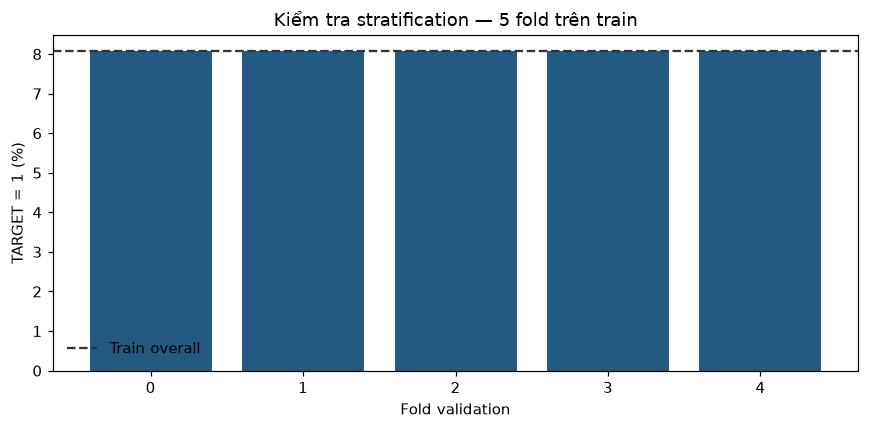

In [15]:
targets = labels_df.set_index(ID_COL)[TARGET_COL]
split_summary_df = pd.DataFrame([
    {"split": name, "n_rows": len(ids), "fraction": len(ids) / len(labels_df),
     "n_positive": int(targets.loc[ids].sum()), "positive_rate": float(targets.loc[ids].mean())}
    for name, ids in [("train", train_split[ID_COL]), ("val", val_split[ID_COL])]
])
save_report(split_summary_df, "train_val_summary.csv")
display(split_summary_df.round(6))
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(fold_summary.fold.astype(str), fold_summary.fold_valid_positive_rate * 100, color="#245A81")
ax.axhline(fold_summary.train_positive_rate.iloc[0] * 100, color="#333333", linestyle="--", label="Train overall")
ax.set(title="Kiểm tra stratification — 5 fold trên train", xlabel="Fold validation", ylabel="TARGET = 1 (%)")
ax.set_ylim(bottom=0)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()


## 6. Bàn giao và giới hạn
- Đã kiểm kê tám bảng; xem bảng benchmark, overview, thông tin cột và kiểm tra khóa ở trên.
- Các khóa không đạt và FK orphan phải được xem xét ở notebook làm sạch; notebook này không sửa dữ liệu.
- `train.parquet` và `val.parquet` chỉ chứa membership theo khách hàng. Các bước fit imputation,
  encoding, scaling hoặc chọn đặc trưng sau này phải dùng fold-training; holdout được giữ cho đánh giá cuối.
- Các bảng CSV được xuất vào `reports/tables/` khi `EXPORT_REPORTS=True`; không ghi vào `data/dictionaries/`.
- Không xóa, di chuyển hoặc ghi đè các artifact cũ. Không có kết quả huấn luyện trong notebook này.
- Thời gian benchmark phụ thuộc máy và cache; không suy rộng thành tốc độ pipeline huấn luyện.

### Kết quả lần kiểm tra trên dữ liệu hiện tại
- Đã chạy 13 code cell trên đủ 8 bảng; tái sử dụng Parquet có sẵn. Nhánh tạo Parquet mới chưa được chạy trên bộ raw này.
- Bảy khóa dự kiến đạt NOT NULL + UNIQUE; tổ hợp chẩn đoán của installments_payments không đạt.
- Có 3.120.184 dòng bureau_balance không khớp bureau; lịch sử POS, installments và credit card cũng có SK_ID_PREV không có trong previous_application. Các bảng kết quả phía trên ghi rõ số lượng; không tự xóa các dòng này.
- Giữ nguyên phân chia cũ: train 246.008 khách hàng, val 61.503 khách hàng; lấy 5 fold của seed 42.
- Lượt kiểm tra này đặt EXPORT_REPORTS=False để chỉ ghi trong data/ và notebooks/. Khi chạy bình thường, giá trị mặc định True sẽ xuất bảng CSV vào reports/tables/.
